In [1]:
import json
import time
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras

from common import contract, data, metrics, paths, plots
import mlp

plots.aplicar_estilo()

SEMENTE = contract.SEED
FEATURES = mlp.ENTRADAS
GRANULARIDADES = contract.GRANULARIDADES           # ("5min", "10min", "1h", "1D")
ROTULO = contract.GRANULARIDADE_LABEL

OCULTAS = (128, 64, 32)

# Valores por granularidade. "10min" e' interpolacao entre 5min (400/512/60/3e-4)
# e 1h (300/64/40/5e-4): granularidade mais fina usa batch maior e LR mais alta.
HIPERPARAMETROS = {
    "5min":  dict(EPOCHS=400, BATCH=512, PACIENCIA=60, LR=3e-4),
    "10min": dict(EPOCHS=400, BATCH=256, PACIENCIA=60, LR=3e-4),
    "1h":    dict(EPOCHS=300, BATCH=64,  PACIENCIA=40, LR=5e-4),
    "1D":    dict(EPOCHS=500, BATCH=32,  PACIENCIA=60, LR=1e-3),
}
# Huber delta nao e' parametro de granularidade: e' limiar na escala do residuo.
HUBER_DELTA_FRAC = 0.25

# Os splits mantem PCA == 0 (sentinelas de faltante). O Box-Cox exige alvo
# estritamente positivo; o shift de 1 W poe o zero dentro do dominio sem mudar
# a escala do alvo, e a inversa subtrai o mesmo valor.
SHIFT_ALVO = 0.001   # kW

keras.utils.set_random_seed(SEMENTE)
np.random.seed(SEMENTE)

print("tensorflow", tf.__version__, "| keras", keras.__version__)
print(f"entradas: {len(FEATURES)} -> {', '.join(FEATURES)}")
print("splits  : train (2021..2024H1) | calibration (2024H2) | test (2025)")
print(f"granularidades: {', '.join(ROTULO[f] for f in GRANULARIDADES)}")
print(f"shift do alvo (Box-Cox): +{SHIFT_ALVO} kW")


tensorflow 2.21.0 | keras 3.15.1
entradas: 3 -> temperatura_ambiente, ghit, jacques
splits  : train (2021..2024H1) | calibration (2024H2) | test (2025)
granularidades: 5 min, 10 min, 1 h, 1 d
shift do alvo (Box-Cox): +0.001 kW


In [2]:
from scipy.stats import boxcox
from scipy.special import inv_boxcox

ALVO = contract.TARGET
PCA_MIN, PCA_MAX = data.physical_target_limits()

def para_kw(pred_bc, lmbda, clip_bc):
    """Box-Cox -> kW, com clip seguro antes da inversa, e sem o shift."""
    return inv_boxcox(np.clip(pred_bc, *clip_bc), lmbda) - SHIFT_ALVO

dados = {}
for freq in GRANULARIDADES:
    treino = data.load_split("train", freq=freq)
    calibracao = data.load_split("calibration", freq=freq)
    teste = data.load_split("test", freq=freq)

    # Min-max ajustado SO no treino (2021..2024H1); calibracao e teste usam as
    # mesmas constantes. O maximo vira minimo + 1 numa coluna constante.
    minimo = treino[list(FEATURES)].min()
    maximo = treino[list(FEATURES)].max()
    maximo = maximo.where(maximo > minimo, minimo + 1.0)

    def escala(d):
        return ((d[list(FEATURES)] - minimo) / (maximo - minimo)).to_numpy(np.float32)

    X_tre, y_tre = escala(treino), treino[ALVO].to_numpy(np.float32)
    X_cal, y_cal = escala(calibracao), calibracao[ALVO].to_numpy(np.float32)
    X_tes, y_tes = escala(teste), teste[ALVO].to_numpy(np.float32)

    # Shift + Box-Cox: o lambda e' ajustado SO no treino (do alvo com shift) e
    # aplicado a calibracao e ao teste com as mesmas constantes.
    y_tre_bc, LAMBDA = boxcox(y_tre + SHIFT_ALVO)
    y_cal_bc = boxcox(y_cal + SHIFT_ALVO, lmbda=LAMBDA)
    y_tes_bc = boxcox(y_tes + SHIFT_ALVO, lmbda=LAMBDA)

    # A inversa so' existe para 1 + lambda*y > 0. O clip usa o dominio valido e
    # a faixa do treino; target_limits() NAO serve (a folga cai fora do dominio).
    DOMINIO_MIN = (-1.0 / LAMBDA + 1e-9) if abs(LAMBDA) > 1e-8 else -np.inf
    CLIP_BC = (max(float(y_tre_bc.min()), DOMINIO_MIN), float(y_tre_bc.max()))

    HUBER_DELTA = HUBER_DELTA_FRAC * float(
        np.quantile(y_tre_bc, .75) - np.quantile(y_tre_bc, .25))

    dados[freq] = dict(
        treino=treino, calibracao=calibracao, teste=teste,
        X_tre=X_tre, y_tre=y_tre, y_tre_bc=y_tre_bc,
        X_cal=X_cal, y_cal_bc=y_cal_bc, X_tes=X_tes, y_tes=y_tes,
        y_tes_bc=y_tes_bc, lmbda=LAMBDA, clip_bc=CLIP_BC,
        huber=HUBER_DELTA, minimo=minimo, maximo=maximo,
    )

    print(f"{ROTULO[freq]:>6} | treino {len(y_tre):6} | calibracao {len(y_cal):5} "
          f"| teste {len(y_tes):5} | PCA {y_tre.min():.3f}..{y_tre.max():.2f} kW "
          f"| lambda {LAMBDA:.6f} | huber {HUBER_DELTA:.3f}")

assert all(d["X_tre"].dtype == np.float32 for d in dados.values())
print("OK: X em [0, 1] (min-max ajustado so no treino), alvo = shift + Box-Cox por granularidade")


 5 min | treino 156974 | calibracao 22550 | teste 44956 | PCA 0.000..2.00 kW | lambda 0.566174 | huber 0.261
10 min | treino  79078 | calibracao 11366 | teste 22637 | PCA 0.000..2.00 kW | lambda 0.613057 | huber 0.246
   1 h | treino  14133 | calibracao  2033 | teste  4042 | PCA 0.000..1.97 kW | lambda 0.649431 | huber 0.233
   1 d | treino   1250 | calibracao   182 | teste   354 | PCA 0.000..1.32 kW | lambda 1.422198 | huber 0.080
OK: X em [0, 1] (min-max ajustado so no treino), alvo = shift + Box-Cox por granularidade


In [3]:
def construir(lr, huber, media_y):
    camadas = [keras.layers.Input(shape=(len(FEATURES),), name="features")]
    for i, n in enumerate(OCULTAS):
        camadas.append(keras.layers.Dense(n, activation="gelu", name=f"oculta_{i}"))
        camadas.append(keras.layers.Dropout(0.1))
    # A saida da rede esta no espaco Box-Cox (nao em kW): media_y e' a media do
    # alvo transformado, e a inversa/shift/offset sao aplicados fora do modelo.
    camadas.append(keras.layers.Dense(
        1, name="pca_kw",
        bias_initializer=keras.initializers.Constant(media_y)))
    modelo = keras.Sequential(camadas, name="knob_senses_pca")
    modelo.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss=keras.losses.Huber(delta=huber),
        metrics=[keras.metrics.RootMeanSquaredError(name="rmse"), "mae"],
    )
    return modelo

historicos = {}
for freq in GRANULARIDADES:
    d = dados[freq]
    cfg = HIPERPARAMETROS[freq]
    d["modelo"] = construir(cfg["LR"], d["huber"], float(d["y_tre_bc"].mean()))

    chamadas = [
        keras.callbacks.EarlyStopping(monitor="val_mae", patience=cfg["PACIENCIA"]*2,
                                      restore_best_weights=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=8,
                                          min_lr=1e-8, verbose=0),
    ]
    t0 = time.perf_counter()
    # Validacao temporal (2024H2), nao o split aleatorio por linha.
    historico = d["modelo"].fit(
        d["X_tre"], d["y_tre_bc"],
        validation_data=(d["X_cal"], d["y_cal_bc"]),
        epochs=cfg["EPOCHS"], batch_size=cfg["BATCH"], callbacks=chamadas, verbose=0,
    )
    historicos[freq] = historico
    print(f"{ROTULO[freq]:>6} | {time.perf_counter() - t0:6.1f} s | "
          f"parou na epoca {len(historico.history['loss'])} "
          f"(melhor val_mae {min(historico.history['val_mae']):.5f}, espaco Box-Cox)")

# A arquitetura e' a mesma em todas as granularidades.
dados[GRANULARIDADES[2]]["modelo"].summary()


 5 min |  485.7 s | parou na epoca 155 (melhor val_mae 0.21037, espaco Box-Cox)
10 min |  306.5 s | parou na epoca 142 (melhor val_mae 0.16596, espaco Box-Cox)
   1 h |   94.0 s | parou na epoca 82 (melhor val_mae 0.12079, espaco Box-Cox)
   1 d |   53.7 s | parou na epoca 130 (melhor val_mae 0.07813, espaco Box-Cox)


Model: "knob_senses_pca"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_0 (Dense)                │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pca_kw (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,645 (127.52 KB)

 Trainable params: 10,881 (42.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 21,764 (85.02 KB)

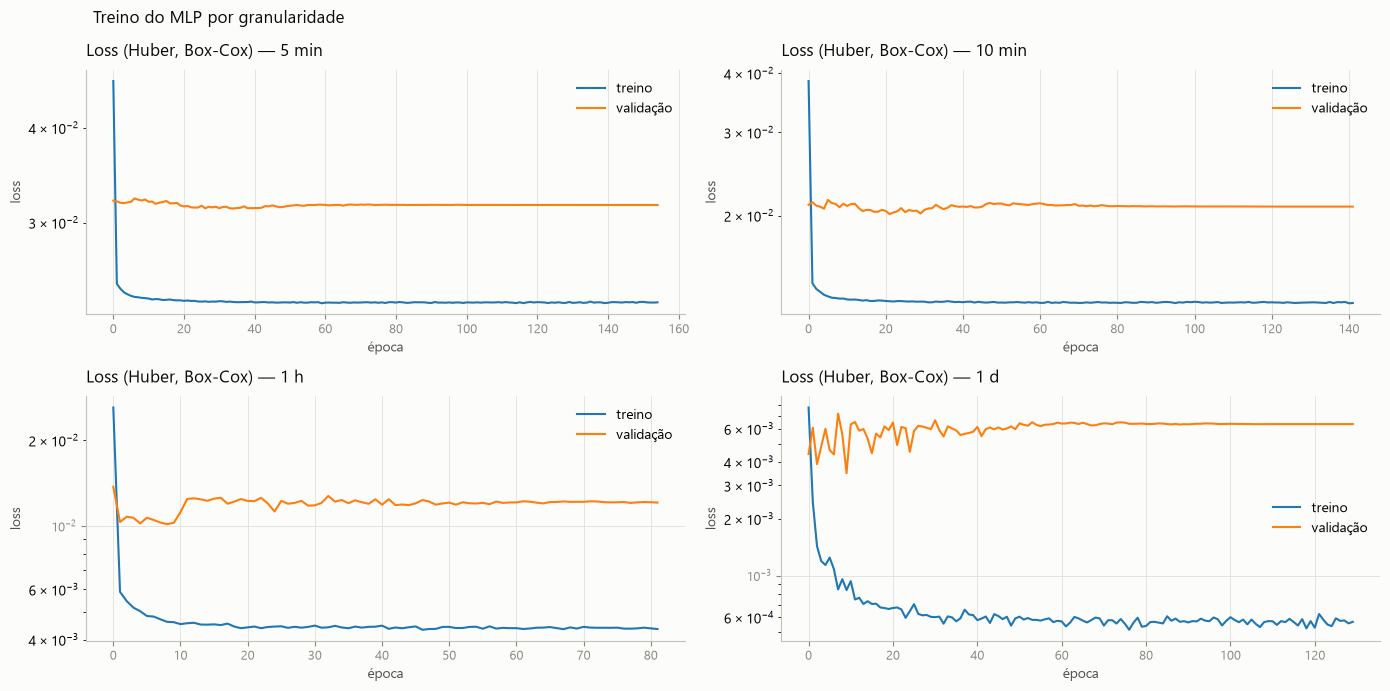

In [4]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 7))
for eixo, freq in zip(eixos.ravel(), GRANULARIDADES):
    h = historicos[freq]
    eixo.plot(h.history["loss"], label="treino")
    eixo.plot(h.history["val_loss"], label="validação")
    eixo.set_yscale("log")
    plots.enfeitar(eixo, f"Loss (Huber, Box-Cox) — {ROTULO[freq]}", "época", "loss")
    eixo.legend(frameon=False)
fig.suptitle("Treino do MLP por granularidade", x=0.07, ha="left", color=plots.TINTA)
fig.tight_layout()
plt.show()
fig.savefig(paths.ROOT / 'docs' / 'figuras' / 'mlp_treino_granularidades.png',
            dpi=200, bbox_inches='tight')


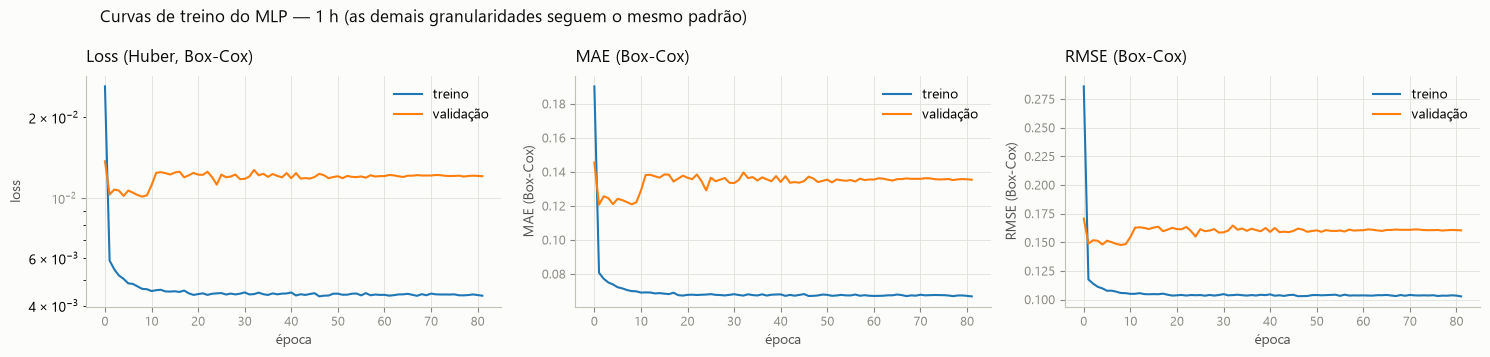

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
for eixo, chave, titulo, ylabel in (
    (eixos[0], "loss", "Loss (Huber, Box-Cox)", "loss"),
    (eixos[1], "mae", "MAE (Box-Cox)", "MAE (Box-Cox)"),
    (eixos[2], "rmse", "RMSE (Box-Cox)", "RMSE (Box-Cox)"),
):
    eixo.plot(historicos["1h"].history[chave], label="treino")
    eixo.plot(historicos["1h"].history[f"val_{chave}"], label="validação")
    plots.enfeitar(eixo, titulo, "época", ylabel)
    eixo.legend(frameon=False)
eixos[0].set_yscale("log")
fig.suptitle("Curvas de treino do MLP — 1 h (as demais granularidades seguem o mesmo padrão)",
             x=0.07, ha="left", color=plots.TINTA)
fig.tight_layout()
plt.show()
fig.savefig(paths.ROOT / 'docs' / 'figuras' / 'mlp_treino_1h.png',
            dpi=200, bbox_inches='tight')


In [6]:
# Um subdiretorio por granularidade em dist/: modelo.keras + transformacao_alvo.json.
# O export para o Edge Impulse (mlp.export) tambem recebe o destino por freq.
SAIDA = paths.EXPORT_MLP

for freq in GRANULARIDADES:
    d = dados[freq]
    modelo = d["modelo"]

    # Calibracao do vies em kW: offset = media(real - previsto) na calibracao
    # (2024H2). A saida da rede esta em Box-Cox, entao NAO da' para somar o
    # offset no bias da camada de saida; invertemos a previsao e medimos em kW.
    pred_cal_bc = modelo.predict(d["X_cal"], batch_size=512, verbose=0).ravel()
    y_cal_kw = inv_boxcox(d["y_cal_bc"], d["lmbda"]) - SHIFT_ALVO
    OFFSET_CALIBRACAO = float(np.mean(y_cal_kw - para_kw(pred_cal_bc, d["lmbda"], d["clip_bc"])))
    d["offset"] = OFFSET_CALIBRACAO

    destino = SAIDA / freq
    destino.mkdir(parents=True, exist_ok=True)

    # Checkpoint Keras: salva o modelo treinado e recarrega antes do teste.
    # O modelo salvo devolve BOX-COX; a inversa, o shift, o clip e o offset vao
    # no sidecar (e no normalizacao.json do export, se ele for chamado).
    caminho_modelo = destino / "modelo.keras"
    modelo.save(caminho_modelo)
    modelo_carregado = keras.models.load_model(caminho_modelo, compile=False)
    n = min(256, len(d["X_tes"]))
    assert np.allclose(modelo.predict(d["X_tes"][:n], verbose=0),
                       modelo_carregado.predict(d["X_tes"][:n], verbose=0), atol=1e-6)
    d["modelo_carregado"] = modelo_carregado

    transformacao = {
        "tipo": "shift + boxcox",
        "shift_kw": SHIFT_ALVO,
        "lambda": float(d["lmbda"]),
        "inversa": "y_kw = (1 + lambda*y_bc)**(1/lambda) - shift_kw",
        "clip_boxcox": [float(d["clip_bc"][0]), float(d["clip_bc"][1])],
        "offset_kw": float(OFFSET_CALIBRACAO),
        "pca_min_kw": float(PCA_MIN),
        "pca_max_kw": float(PCA_MAX),
        "features": list(FEATURES),
        "freq": freq,
        "granularidade": ROTULO[freq],
        "ajustado_em": "treino 2021..2024H1",
        "calibracao_em": "2024H2",
        "pos_processamento": ("clip_boxcox -> inv_boxcox -> - shift_kw -> "
                              "+ offset_kw -> clip(pca_min_kw, pca_max_kw)"),
    }
    caminho_transformacao = destino / "transformacao_alvo.json"
    caminho_transformacao.write_text(
        json.dumps(transformacao, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

    print(f"{ROTULO[freq]:>6} | offset {OFFSET_CALIBRACAO:+.4f} kW | "
          f"{caminho_modelo.relative_to(paths.ROOT)} "
          f"({caminho_modelo.stat().st_size / 1024:.1f} KB) | "
          f"{caminho_transformacao.relative_to(paths.ROOT)}")


 5 min | offset -0.0827 kW | dist\5min\modelo.keras (164.1 KB) | dist\5min\transformacao_alvo.json
10 min | offset -0.0913 kW | dist\10min\modelo.keras (164.1 KB) | dist\10min\transformacao_alvo.json
   1 h | offset -0.0881 kW | dist\1h\modelo.keras (164.1 KB) | dist\1h\transformacao_alvo.json
   1 d | offset -0.0731 kW | dist\1D\modelo.keras (164.1 KB) | dist\1D\transformacao_alvo.json


MLP 5 min            MAE 0.1630 kW | RMSE 0.2470 kW | R2 0.7967 | vies +0.0081 kW
MLP 10 min           MAE 0.1142 kW | RMSE 0.1580 kW | R2 0.9104 | vies +0.0051 kW
MLP 1 h              MAE 0.0623 kW | RMSE 0.0784 kW | R2 0.9751 | vies +0.0050 kW
MLP 1 d              MAE 0.0306 kW | RMSE 0.0436 kW | R2 0.9498 | vies +0.0083 kW


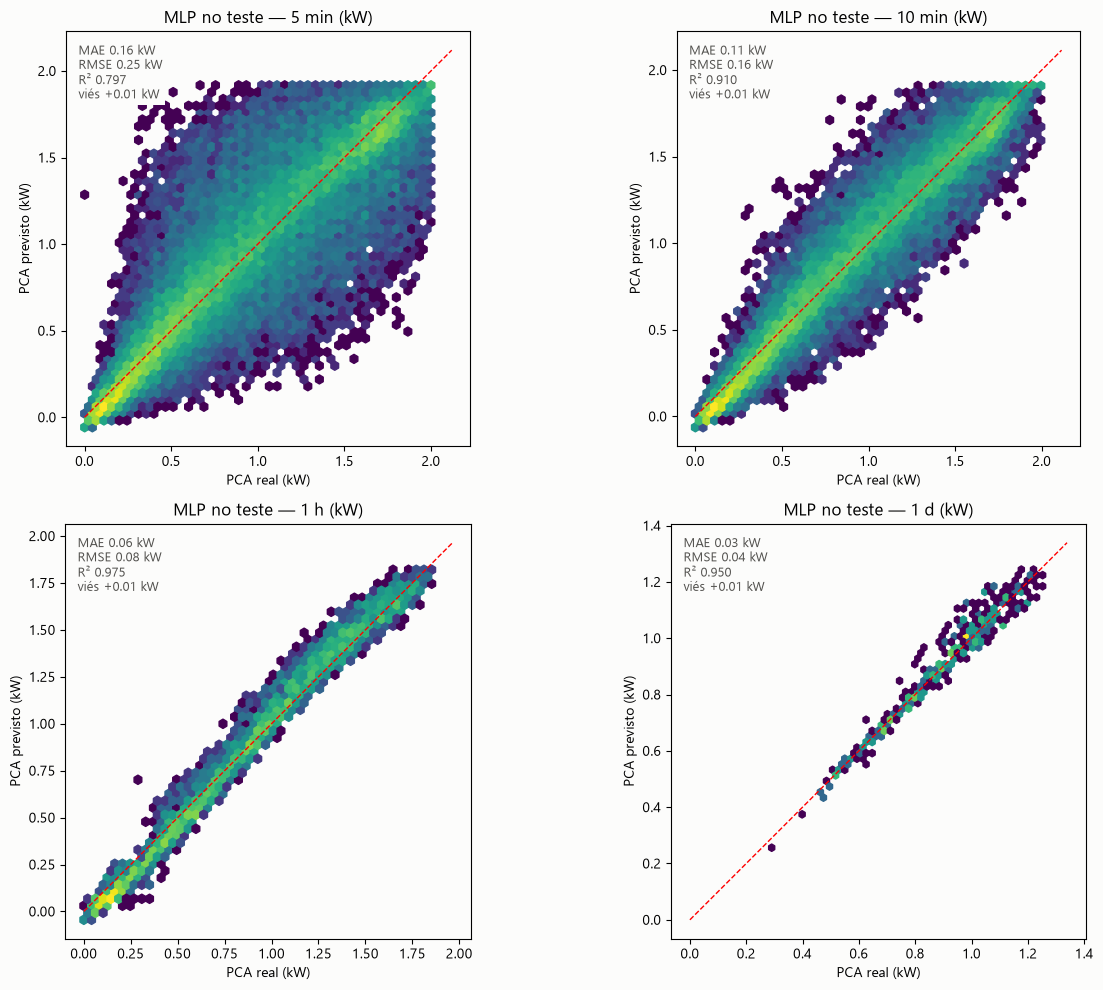

granularidade  freq  lambda  offset (kW)  epocas  MAE (kW)  RMSE (kW)     R2  vies (kW)
        5 min  5min  0.5662      -0.0827     155    0.1630     0.2470 0.7967     0.0081
       10 min 10min  0.6131      -0.0913     142    0.1142     0.1580 0.9104     0.0051
          1 h    1h  0.6494      -0.0881      82    0.0623     0.0784 0.9751     0.0050
          1 d    1D  1.4222      -0.0731     130    0.0306     0.0436 0.9498     0.0083


In [7]:
avaliacoes, series = {}, {}
for freq in GRANULARIDADES:
    d = dados[freq]
    pred_bc = d["modelo_carregado"].predict(d["X_tes"], batch_size=512, verbose=0).ravel()
    pred = para_kw(pred_bc, d["lmbda"], d["clip_bc"]) + d["offset"]   # Box-Cox -> kW -> calibracao
    y_tes_kw = inv_boxcox(d["y_tes_bc"], d["lmbda"]) - SHIFT_ALVO

    avaliacoes[freq] = metrics.evaluate(f"MLP {ROTULO[freq]}", y_tes_kw, pred,
                                        pca_min=PCA_MIN, pca_max=PCA_MAX)
    series[freq] = (y_tes_kw, pred)

fig, eixos = plt.subplots(2, 2, figsize=(13, 10))
for eixo, freq in zip(eixos.ravel(), GRANULARIDADES):
    y, p = series[freq]
    r = avaliacoes[freq]
    plots.hexbin_real_vs_pred(eixo, y, p, f"MLP no teste — {ROTULO[freq]} (kW)")
    texto = chr(10).join([
        f"MAE {r['MAE (kW)']:.2f} kW",
        f"RMSE {r['RMSE (kW)']:.2f} kW",
        f"R² {r['R2']:.3f}",
        f"viés {r['vies (kW)']:+.2f} kW",
    ])
    eixo.text(0.03, 0.97, texto, transform=eixo.transAxes, va="top",
              color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
fig.tight_layout()
plt.show()
fig.savefig(paths.ROOT / 'docs' / 'figuras' / 'mlp_avaliacao_granularidades.png',
            dpi=200, bbox_inches='tight')

tabela = pd.DataFrame([
    {
        "granularidade": ROTULO[freq],
        "freq": freq,
        "lambda": dados[freq]["lmbda"],
        "offset (kW)": dados[freq]["offset"],
        "epocas": len(historicos[freq].history["loss"]),
        "MAE (kW)": avaliacoes[freq]["MAE (kW)"],
        "RMSE (kW)": avaliacoes[freq]["RMSE (kW)"],
        "R2": avaliacoes[freq]["R2"],
        "vies (kW)": avaliacoes[freq]["vies (kW)"],
    }
    for freq in GRANULARIDADES
])
print(tabela.round(4).to_string(index=False))


In [ ]:
# Analise cruzada de granularidades: cada modelo treinado avalia no teste das
# QUATRO granularidades. As entradas do teste de B sao reescaladas com o
# min-max do treino de A (fora do [0, 1] quando B e' mais fino que A: o modelo
# extrapola, e e' exatamente isso que a analise mede). A diagonal e' o proprio
# modelo; abaixo dela, modelo grosso avaliado em dado fino.
cruzada = []
for freq_a in GRANULARIDADES:
    dA = dados[freq_a]
    modelo_a = dA["modelo_carregado"]
    linha = {"treinado": ROTULO[freq_a]}
    for freq_b in GRANULARIDADES:
        dB = dados[freq_b]
        X_b = ((dB["teste"][list(FEATURES)] - dA["minimo"])
               / (dA["maximo"] - dA["minimo"])).to_numpy(np.float32)
        pred_bc = modelo_a.predict(X_b, batch_size=512, verbose=0).ravel()
        pred = para_kw(pred_bc, dA["lmbda"], dA["clip_bc"]) + dA["offset"]
        r = metrics.evaluate(f"A={freq_a} em B={freq_b}", dB["y_tes"], pred,
                             pca_min=PCA_MIN, pca_max=PCA_MAX)
        linha[ROTULO[freq_b]] = r["MAE (kW)"]
        linha[f"{ROTULO[freq_b]} R2"] = r["R2"]
    cruzada.append(linha)

tabela_cruzada = pd.DataFrame(cruzada)
colunas = ["treinado", *[ROTULO[f] for f in GRANULARIDADES]]
print("MAE (kW) por par treinado x avaliado:")
print(tabela_cruzada[colunas].round(4).to_string(index=False))

fig, eixo = plt.subplots(figsize=(7, 5.5))
m = tabela_cruzada.set_index("treinado")[[ROTULO[f] for f in GRANULARIDADES]]
eixo.imshow(m.to_numpy(), cmap="viridis_r")
eixo.set_xticks(range(len(GRANULARIDADES)), [ROTULO[f] for f in GRANULARIDADES])
eixo.set_yticks(range(len(GRANULARIDADES)), m.index)
for i in range(len(m)):
    for j in range(len(m.columns)):
        eixo.text(j, i, f"{m.iloc[i, j]:.3f}", ha="center", va="center",
                  color="white" if m.iloc[i, j] > m.to_numpy().max() * 0.55 else "black")
plots.enfeitar(eixo, "MAE (kW) — treinado (linha) × avaliado (coluna)",
               "avaliado em", "treinado em")
fig.tight_layout()
fig.savefig(paths.ROOT / "docs" / "figuras" / "mlp_cruzada.png",
            dpi=200, bbox_inches="tight")
plt.show()
